# 1. Ocean section and physical question
This active reconstruction estimates conditional water-source fractions and biological oxygen consumption at576real GP15 bottle locations. Six tracer signatures constrain eleven latent quantities. Fractions represent mixing, not a new direct measurement. Author-supplied source properties,coordinates and reaction stoichiometry are visible calibration. We select the complete documented nine-source author example, not the final later subtype/circulation-model analysis.

### Data and units
| Quantity | Shape without batch | Unit | Role |
|---|---|---|---|
| Tracer observations Y |576 by6| degC; PSS-78; micromole/kg for Si,N,P,O2 | Real bottle measurements |
| Source dictionary M |9 by6| Same tracer units as Y | Author supplied source calibration |
| Reaction ratios C |2 by6| Each tracer unit per micromole O2/kg | Fixed stoichiometry |
| Coordinates |576 by4| latitude/longitude deg; depth m; sigma0 kg/m3 anomaly | Observed prior coordinates |
| Source fractions F |576 by9| dimensionless | Unknown conditional mixture |
| Reaction magnitudes R |576 by2| micromole O2/kg | Unknown nonnegative oxygen consumption |

Tracer order is potential temperature, practical salinity, silicate, nitrate, phosphate, dissolved oxygen. Station locations are discrete observations; section plots do not create new sampled sites.

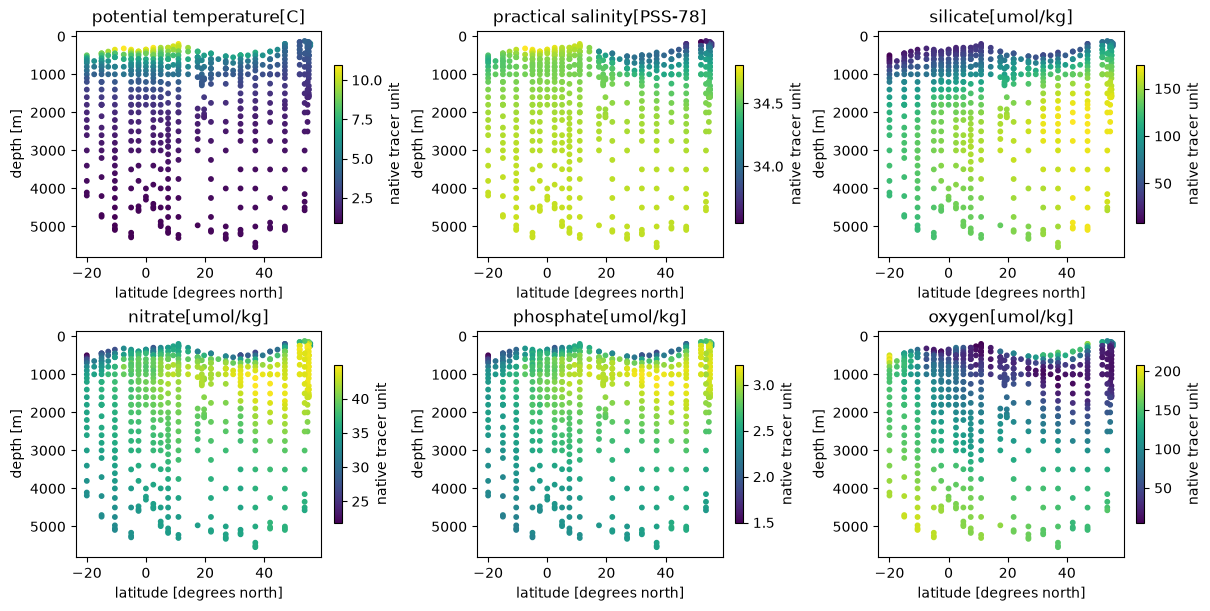

Samples: 576 sources: ('AAIW', 'PSUW', 'ESSW', 'NPIW', 'PDW1', 'UCDW', 'PDW23', 'LCDW', 'AABW') latitude/depth bounds: [-20.         123.25588139] [  55.5958     5544.95611573]


In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load
from src.solvers import reconstruct
from src.physics_model import predict,usage_penalties,NAMES
from src.visualization import section_panels
d=load();coords=d['sample_coordinates'];y=d['observations'];w=d['tracer_weights'];P=usage_penalties(coords)
tracers=['potential temperature[C]','practical salinity[PSS-78]','silicate[umol/kg]','nitrate[umol/kg]','phosphate[umol/kg]','oxygen[umol/kg]']
section_panels(coords,y,tracers,'native tracer unit');plt.show()
print('Samples:',len(y),'sources:',NAMES,'latitude/depth bounds:',coords[:,[0,2]].min(0),coords[:,[0,2]].max(0))

# 2. Physical model, constraints and objective
For bottle i and tracer j, M(k,j) is source k's signature and C(a,j) is the change in tracer j per unit of reaction channel a. F(i,k) is the source fraction and R(i,a) is the nonnegative reaction magnitude:

$$\widehat Y_{ij}=\sum_{k=1}^{9}F_{ik}M_{kj}+\sum_{a=1}^{2}R_{ia}C_{aj},\qquad \widehat Y=FM+RC.$$

Both channels consume oxygen and regenerate nitrate/phosphate according to the visible supplied ratios. Their mixture permits variable effective nutrient regeneration. Source fractions conserve water mass:

$$F_{ik}\ge0,\qquad \sum_{k=1}^{9}F_{ik}=1,\qquad R_{ia}\ge0.$$

Let w(j) be the supplied tracer weight and P(i,k) the geographic usage penalty computed from bottle coordinates. Each independent bottle minimizes

$$J_i=\sum_{j=1}^{6}\left[w_j(\widehat Y_{ij}-Y_{ij})\right]^2+\sum_{k=1}^{9}\left[P_{ik}F_{ik}\right]^2,\qquad J=\sum_{i=1}^{576}J_i.$$

Weights56,80,3,5,5,1 multiply native-unit T,S,Si,N,P,O2 residuals. They are selected analysis scales in reciprocal tracer units, not independently measured noise deviations. Penalty terms are dimensionless usage discouragement, not true source fractions. LCDW/AABW depend on measured density; PSUW depends on observed latitude/depth. These priors condition the solution. No spatial interpolation or hidden fractions enter the inverse problem.


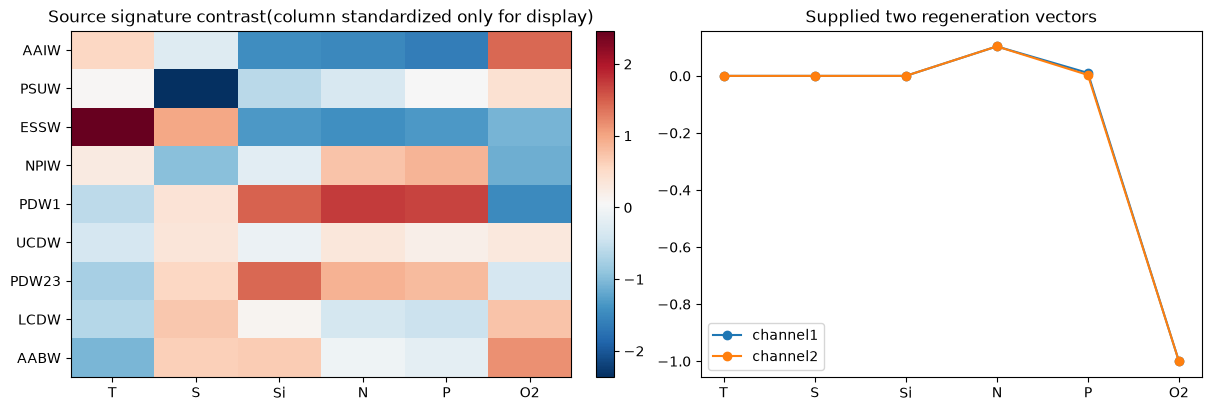

Independent upstream prior max error 1.7053025658242404e-13


In [2]:
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
M=d['endmembers'];im=axs[0].imshow((M-M.mean(0))/np.maximum(M.std(0),1e-12),aspect='auto',cmap='RdBu_r');axs[0].set_xticks(range(6),['T','S','Si','N','P','O2']);axs[0].set_yticks(range(9),NAMES);axs[0].set_title('Source signature contrast(column standardized only for display)');fig.colorbar(im,ax=axs[0])
axs[1].plot(d['reaction_ratios'].T,'o-');axs[1].set_xticks(range(6),['T','S','Si','N','P','O2']);axs[1].set_title('Supplied two regeneration vectors');axs[1].legend(['channel1','channel2']);plt.show()
with np.load('test/fixtures/upstream_stages.npz') as f:
 print('Independent upstream prior max error',np.max(np.abs(P-f['output_penalties'])))

# 3. Active constrained reconstruction
We minimize the exact physical quadratic with analytic gradients, hard mass conservation and nonnegative components. A general numerical QP method is sufficient; the shipped implementation uses SLSQP. No trained model,hidden standard fractions or upstream domain package is loaded by the local reconstruction. Every plotted value below is freshly computed.

Fresh runtime seconds 0.7251449999166653 iteration range 4 62 maximum mass error 4.218847493575595e-15


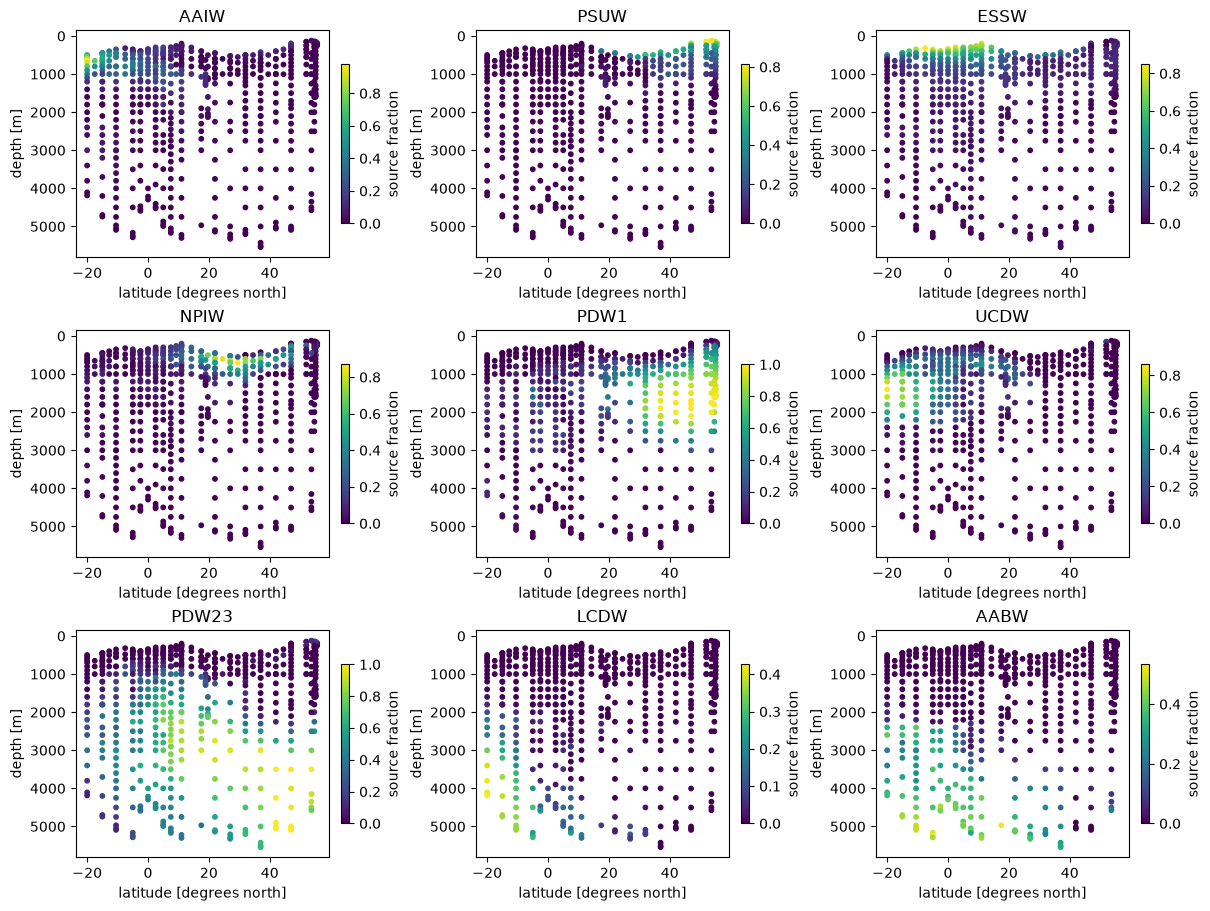

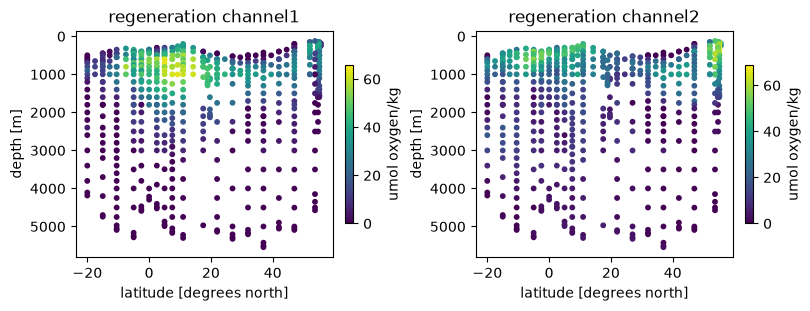

In [3]:
t=time.perf_counter();F,R,it=reconstruct(d);elapsed=time.perf_counter()-t
np.savez('output/reconstruction.npz',reconstruction=F,remineralization=R)
print('Fresh runtime seconds',elapsed,'iteration range',it.min(),it.max(),'maximum mass error',abs(F.sum(2)-1).max())
section_panels(coords,F[0],list(NAMES),'source fraction');plt.show()
section_panels(coords,R[0],['regeneration channel1','regeneration channel2'],'umol oxygen/kg',ncols=2);plt.show()

# 4. Independent source run and identifiability
The archived comparison is an actual current-author-source CVXPY run on these exact576samples and the same weights,source dictionary,reaction constraints and all geographic priors. It is not independent physical truth. The source solve normalizes/clips its returned fractions,so its printed internal objective and the objective recomputed from returned arrays differ slightly. We recompute both source and fresh objectives consistently. Individual fractions can differ in underdetermined directions; equivalent or lower-cost feasible solutions are accepted.

Actual upstream returned objective: 25365.723928276297 fresh: 25365.716110241323 maximum normalized excess: 1.1765039550082058e-07


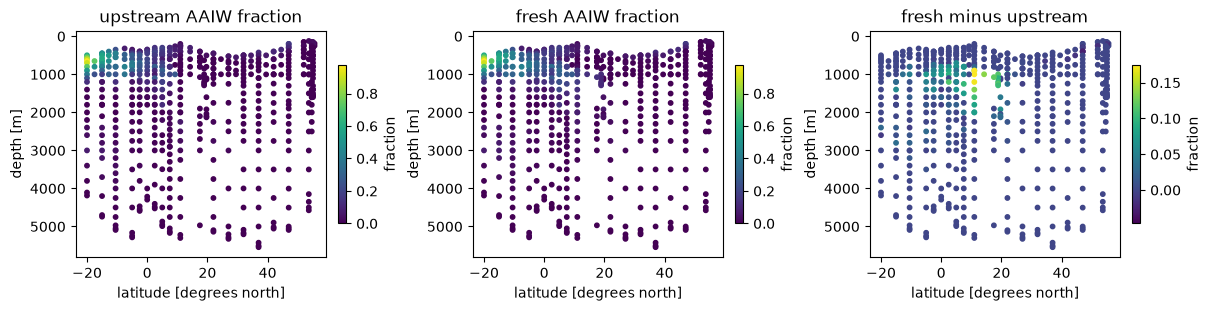

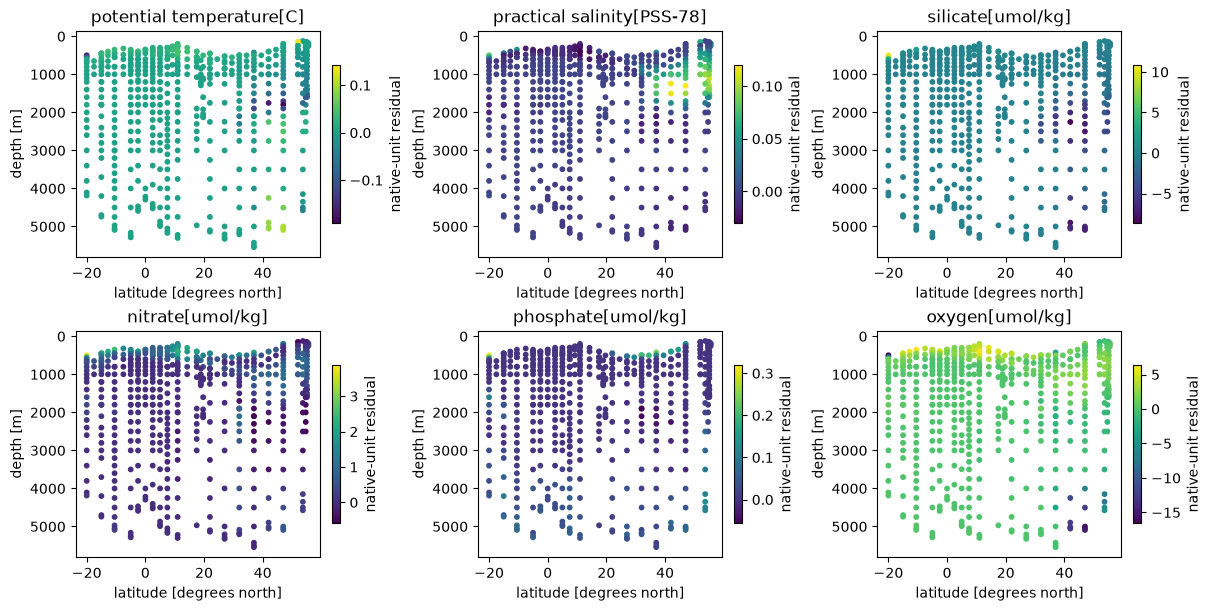

| Actual method | Full declared objective (1) | Max row normalized excess (1) | Max mass error (1) |
|---|---:|---:|---:|
| reproduced source returned | 25365.7239283 | 0 | 3.33067e-16 |
| fresh local | 25365.7161102 | 1.1765e-07 | 4.21885e-15 |

In [4]:
with np.load('notebooks/reference_outputs/upstream_fit.npz') as f:UF=f['reconstruction'];UR=f['remineralization']
def costs(f,r):
 pred=predict(f[0],r[0],d['endmembers'],d['reaction_ratios']);return np.sum(((pred-y)*w)**2,1)+np.sum((f[0]*P)**2,1)
u=costs(UF,UR);v=costs(F,R)
print('Actual upstream returned objective:',u.sum(),'fresh:',v.sum(),'maximum normalized excess:',np.max((v-u)/np.maximum(1,u)))
section_panels(coords,np.c_[UF[0,:,0],F[0,:,0],F[0,:,0]-UF[0,:,0]],['upstream AAIW fraction','fresh AAIW fraction','fresh minus upstream'],'fraction');plt.show()
res=predict(F[0],R[0],d['endmembers'],d['reaction_ratios'])-y
section_panels(coords,res,tracers,'native-unit residual');plt.show()
from IPython.display import Markdown,display
rows=['| Actual method | Full declared objective (1) | Max row normalized excess (1) | Max mass error (1) |','|---|---:|---:|---:|']
for name,ff,rr,jj in [('reproduced source returned',UF,UR,u),('fresh local',F,R,v)]:
 rows.append(f'| {name} | {jj.sum():.12g} | {np.max((jj-u)/np.maximum(1,u)):.6g} | {np.max(abs(ff.sum(2)-1)):.6g} |')
display(Markdown('\n'.join(rows)))


# 5. Physical ablations and robustness
All alternatives are computed. Omitting source-distribution priors tests geographical regularization. Omitting biological reactions tests whether conservative mixing alone explains nutrient/oxygen signatures. A small independently drawn tracer perturbation of0.01inverse-weight units tests sensitivity within the stated analysis scales; these artificial perturbations are diagnostic only and never replace the bundled observations. The nine fractions need not be uniquely identifiable,even when the six predicted tracers are stable.

Rows: ['standard', 'upstream', 'no usage prior', 'no reactions', 'perturbed tracers'] columns: public objective,unweighted tracer residual norm,mass error
[[2.53657161e+04 6.99108396e+01 4.21884749e-15]
 [2.53657239e+04 6.99108227e+01 3.33066907e-16]
 [4.18858738e+05 6.85378938e+01 3.55271368e-15]
 [8.75277969e+05 7.34330463e+02 1.44328993e-14]
 [2.53659796e+04 6.99072086e+01 5.10702591e-15]]


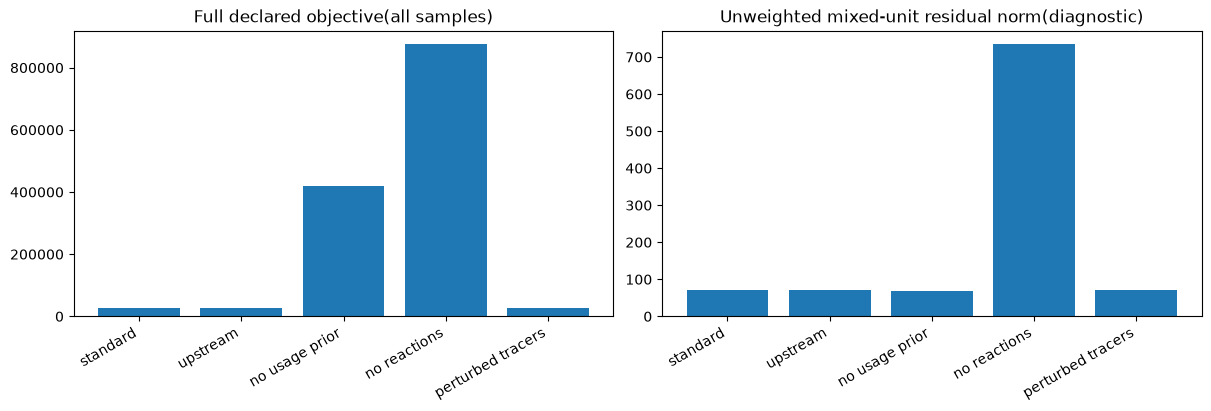

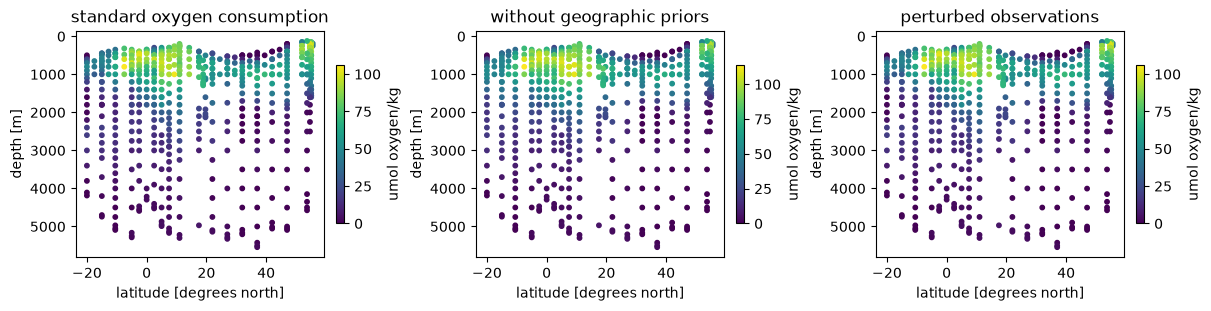

| Computed comparison | Declared objective (1) | Mixed-unit residual norm (diagnostic only) | Max mass error (1) |
|---|---:|---:|---:|
| standard | 25365.7161102 | 69.9108396352 | 4.21884749358e-15 |
| upstream | 25365.7239283 | 69.9108227408 | 3.33066907388e-16 |
| no usage prior | 418858.738052 | 68.5378937718 | 3.5527136788e-15 |
| no reactions | 875277.968586 | 734.330462518 | 1.44328993201e-14 |
| perturbed tracers | 25365.9795726 | 69.9072086489 | 5.10702591328e-15 |

In [5]:
variants={'standard':(F,R),'upstream':(UF,UR)}
fp,rp,_=reconstruct(d,penalty_enabled=False);variants['no usage prior']=(fp,rp)
fn,rn,_=reconstruct(d,reaction_enabled=False);variants['no reactions']=(fn,np.zeros((1,len(y),2)))
pert={k:a.copy() for k,a in d.items()};pert['observations']+=np.random.default_rng(92).normal(size=y.shape)*(.01/w)
fb,rb,_=reconstruct(pert);variants['perturbed tracers']=(fb,rb)
values=np.array([[costs(*pair).sum(),np.linalg.norm(predict(pair[0][0],pair[1][0],d['endmembers'],d['reaction_ratios'])-y),np.max(abs(pair[0].sum(2)-1))] for pair in variants.values()])
print('Rows:',list(variants),'columns: public objective,unweighted tracer residual norm,mass error');print(values)
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,j,title in zip(axs,[0,1],['Full declared objective(all samples)','Unweighted mixed-unit residual norm(diagnostic)']):
 ax.bar(range(len(values)),values[:,j]);ax.set_xticks(range(len(values)),list(variants),rotation=30,ha='right');ax.set_title(title)
plt.show()
section_panels(coords,np.c_[R[0].sum(1),rp[0].sum(1),rb[0].sum(1)],['standard oxygen consumption','without geographic priors','perturbed observations'],'umol oxygen/kg');plt.show()
rows=['| Computed comparison | Declared objective (1) | Mixed-unit residual norm (diagnostic only) | Max mass error (1) |','|---|---:|---:|---:|']
for name,row in zip(variants,values): rows.append('| '+name+' | '+' | '.join(f'{v:.12g}' for v in row)+' |')
display(Markdown('\n'.join(rows)))


# 6. Standalone evaluation and limitations
The Judge checks both outputarrays and all576sample objectives. A simplex or nonnegativity violation fails. It accepts equally good conditional mixtures without matching optimizer identity. No exact independent ocean-source truth is claimed. The selected nine-source example does not implement the later OCIM-based choice of a unique mixture among equivalent solutions. Geographic priors and fixed stoichiometric endmembers condition these maps. No interpolated unobserved grid is evaluated or portrayed as measured data.

In [6]:
import subprocess
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding="utf-8")
print(Path('output/judge_report.json').read_text(encoding="utf-8"));assert p.returncode==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "maximum_normalized_objective_excess": 1.1765039550082058e-07,
    "maximum_simplex_error": 4.218847493575595e-15,
    "minimum_fraction": 0.0,
    "minimum_remineralization": 0.0
  },
  "thresholds": {
    "maximum_normalized_objective_excess": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "maximum_simplex_error": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "minimum_fraction": {
      "comparison": ">=",
      "boundary": -1e-10
    },
    "minimum_remineralization": {
      "comparison": ">=",
      "boundary": -1e-10
    }
  },
  "errors": []
}
